# Geleerde schaalkeuze ×32 of ×64 per MX-blok / A32 — honderd-epochtraining

Deze proef leert **één gedeelde schaalkeuze per MX-blok** voor de twee lagere gewichtsmodi. De actuele E4M3-bron komt uit de FP32-master via de bestaande preprocessing. E2M3 behoudt de hoogste twee exponentbits van die bron. E2M1 ontstaat door twee mantissabits van E2M3 te verwijderen. Beide lagere modi gebruiken dezelfde blokcorrectie: **E8M0-broncode +5 (×32) of +6 (×64)**. De E4M3-bronschaal zelf wordt niet geleerd.

Iedere FP32-hulpwaarde $\theta_b$ start op 6 en blijft in $[5,6]$. De forward kiest $+5$ bij $\theta_b<5{,}5$ en anders $+6$, dus een gelijke waarde kiest ×64. De schaalgradient wordt benaderd als $\ln(2)\sum_{i\in b}g_iq_i$ per lagere modus; de bijdragen van E2M3 en E2M1 worden opgeteld. Na iedere Adam-update volgt projectie op het interval. Er zijn **4.080 extra FP32-hulpwaarden**, met een afzonderlijke Adam-parametergroep en dezelfde beginleersnelheid 0,001. Activaties blijven **A32**; de gedeelde updatemaster en Adam-momenten blijven **FP32**.

Dit notebook leest alleen opgeslagen JSON/CSV. Het start geen training en laadt geen model of checkpoint. De honderd-epochtraining wordt vergeleken met dezelfde gezamenlijk afgewerkte epochs van de bestaande vaste ×32- en ×64-trainingen. Alleen een niet-synthetische, compatibele run krijgt die onderzoeksvergelijking. De notebook is onuitgevoerd meegeleverd; voer zelf alle cellen uit in de resultaatmap.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_learned_scale32_64_reference100\\20261025_150724_515132_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_learned_scale32_64_reference100_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Alle honderd epochs voor alle drie modi aanwezig; volledige referentie volgens het runrapport.** Epoch100 staat naast het door E4M3 gekozen beste checkpoint.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,Actuele E4M3-bron → exponent-MSB-truncatie naa...
2,Geleerde correctie,"Eén FP32 θ per MX-blok; θ∈[5,6], begin6; θ<5,5..."
3,Gedeelde lagere schaal,E2M3 en E2M1 delen dezelfde blokkeuze. De E4M3...
4,Mastergradient,"Identity-STE naar G(W), zonder extra factor32/..."
5,Schaalgradient,ln(2) × som(gradient_q × werkelijk gebruikt q)...
6,Gradientnormalisatie,Geen extra LSQ-normalisatie; geen gemiddelde i...
7,Schaalgrenzen,"θ na Adam projecteren op [5,6]; E8M0-code in b..."
8,Trainbare parameters,132954 basis + 4080 schaalproxies = 137034
9,Activaties / masters / proxies,A32 / FP32 / FP32


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 100 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy binnen de gemeten training**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies dezelfde epoch gerapporteerd; hun eigen hoogste scores worden niet samengevoegd met een andere E4M3-epoch.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 100 staat er apart naast. Bij een onderbroken run staat de laatste gemeten epoch op de plaats van het eindpunt, met een expliciet onvolledig label. Eén run per methode onderbouwt geen significantieclaim.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Epoch 100,100,MXFP8_E4M3,94.933159,24.713 / 26.032,0.208723,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Epoch 100,100,MXFP6_E2M3,94.176398,24.516 / 26.032,0.207699,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Epoch 100,100,MXFP4_E2M1,93.949754,24.457 / 26.032,0.211403,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,34,MXFP8_E4M3,95.013829,24.734 / 26.032,0.186051,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,34,MXFP6_E2M3,93.192993,24.260 / 26.032,0.236067,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,34,MXFP4_E2M1,93.592502,24.364 / 26.032,0.230071,checkpoint_selection.json,best_checkpoint.pt


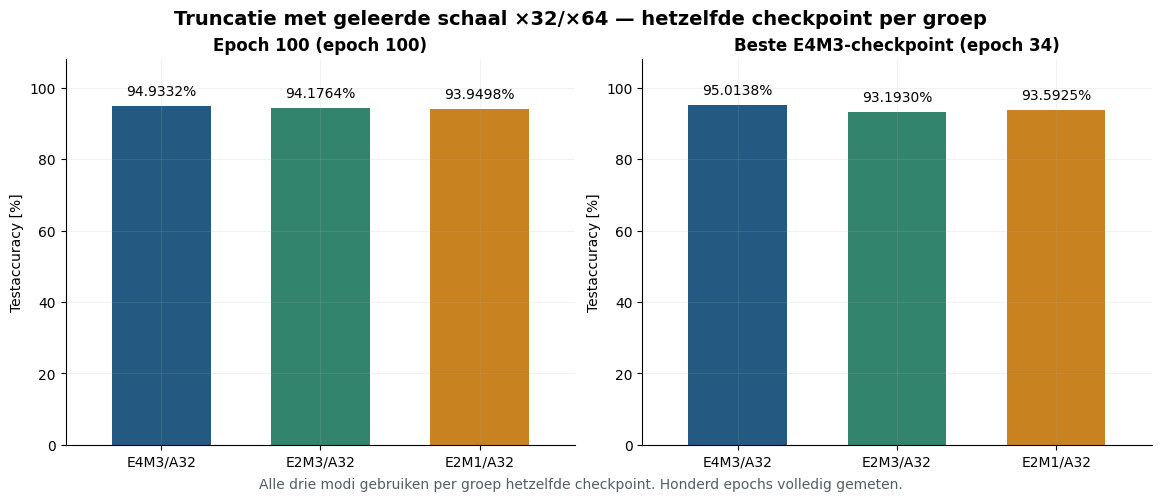

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met vaste ×32 en vaste ×64

De meegeleverde vaste referenties komen uit de twee bestaande honderd-epochtrainingen. Bij een volledige geleerde run vergelijken we de volledige epochrange. Bij een eerdere stop gebruiken we uitsluitend de gezamenlijk afgewerkte epochs; toekomstige referentiescores tellen dan niet mee in de checkpointselectie. De referentiemetrics en herkomstbestanden worden tegen de meegeleverde hashes gecontroleerd.

De staafgrafieken tonen **epoch 100** en **het beste gezamenlijke checkpoint gekozen op E4M3 binnen de beschikbare epochrange**. Die keuze wordt voor iedere training opnieuw berekend. Alle drie modi komen per training uit dat ene checkpoint; de lagere modi kiezen geen eigen beste epoch. Een gedeeltelijke run toont expliciet de laatste gezamenlijke epoch als onvoltooid resultaat. De curves tonen de hele gemeenschappelijke range, zodat een verschil op één checkpoint in context staat.


### Geleerde blokkeuze tegenover vaste ×32 en vaste ×64

De vaste referenties zijn de bestaande volledige honderd-epochtrainingen. Bij een onderbroken geleerde run beperken we iedere referentiecurve en iedere E4M3-selectie tot dezelfde reeds gemeten epochrange. E4M3 kiest per training één gezamenlijk checkpoint; E2M3 en E2M1 gebruiken de scores uit datzelfde checkpoint. 

**×32: vergelijking bevestigd voor epochs 1–100.**

**×64: vergelijking bevestigd voor epochs 1–100.**

Gelijke oorspronkelijke modelstaat en instellingen geven geen bitexacte CUDA-garantie. Eén run per methode geeft geen significantieclaim. De geleerde variant heeft extra schaalparameters.

,Controlepunt,Referentie,Gewichtsformaat,Epoch geleerd,Epoch referentie,Geleerd accuracy [%],Referentie accuracy [%],Verschil geleerd − vast [pp],Geleerd harde CE,Referentie harde CE
0,Epoch 100,Vast ×32,MXFP8_E4M3,100,100,94.933159,94.706515,0.226644,0.208723,0.205240
1,Epoch 100,Vast ×32,MXFP6_E2M3,100,100,94.176398,94.852489,-0.676091,0.207699,0.186292
2,Epoch 100,Vast ×32,MXFP4_E2M1,100,100,93.949754,94.913952,-0.964198,0.211403,0.187656
3,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP8_E4M3,34,55,95.013829,94.844806,0.169023,0.186051,0.198763
4,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP6_E2M3,34,55,93.192993,95.006146,-1.813153,0.236067,0.186000
5,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP4_E2M1,34,55,93.592502,94.775661,-1.183159,0.230071,0.191920
6,Epoch 100,Vast ×64,MXFP8_E4M3,100,100,94.933159,94.929318,0.003841,0.208723,0.209868
7,Epoch 100,Vast ×64,MXFP6_E2M3,100,100,94.176398,94.898586,-0.722188,0.207699,0.189969
8,Epoch 100,Vast ×64,MXFP4_E2M1,100,100,93.949754,94.791026,-0.841272,0.211403,0.193797
9,Beste E4M3 binnen epochs 1–100,Vast ×64,MXFP8_E4M3,34,42,95.013829,95.086816,-0.072987,0.186051,0.193877


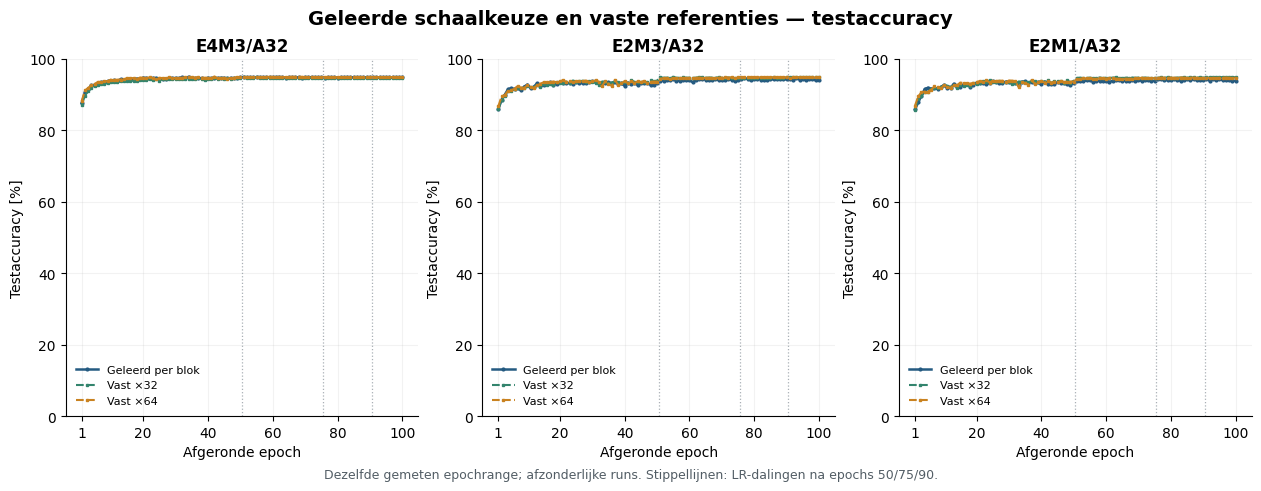

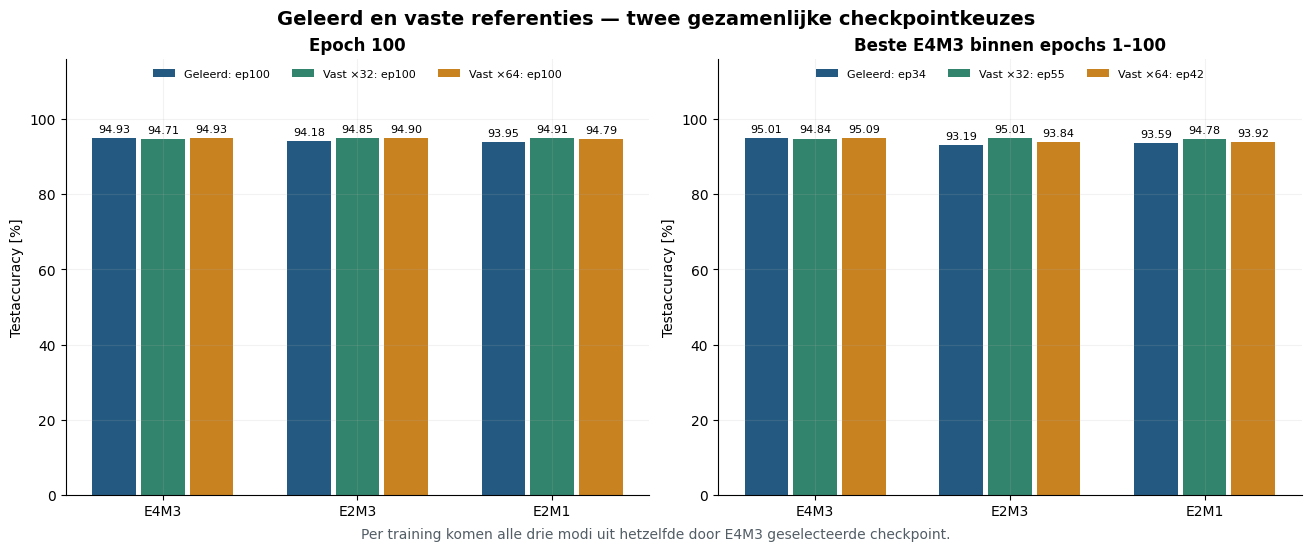

In [4]:
references = ns.load_fixed_references(run)
display(Markdown(ns.comparison_markdown(run, references)))
display(ns.comparison_table(run, references).round(6))
figures['scale_comparison_curves'] = ns.plot_scale_comparison_curves(run, references)
display(figures['scale_comparison_curves'])
plt.close(figures['scale_comparison_curves'])
figures['scale_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, references)
display(figures['scale_comparison_checkpoints'])
plt.close(figures['scale_comparison_checkpoints'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf een nieuwe initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met de opgeslagen harde blokkeuzes, bevroren evaluatiestaat en volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee. De E4M3-route blijft direct uit de actuele bron bepaald; E2M3 en E2M1 volgen dezelfde geleerde blokkeuze.


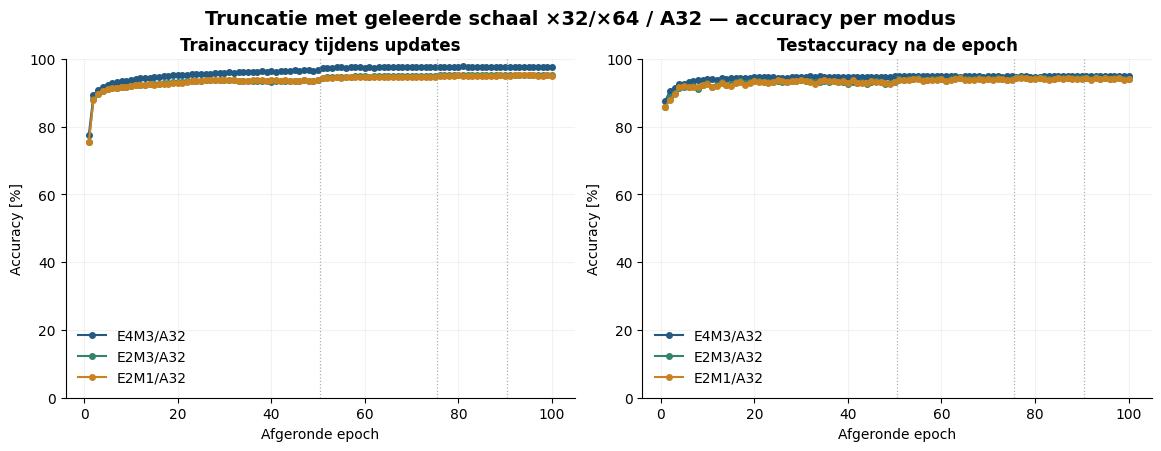

In [5]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.934243
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.900817
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.703496
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.460223
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.455565
...,...,...,...,...,...
595,100,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.187471
596,100,train,MXFP8_E4M3,hard_cross_entropy,0.074980
597,100,test,MXFP4_E2M1,hard_cross_entropy,0.211403
598,100,test,MXFP6_E2M3,hard_cross_entropy,0.207699


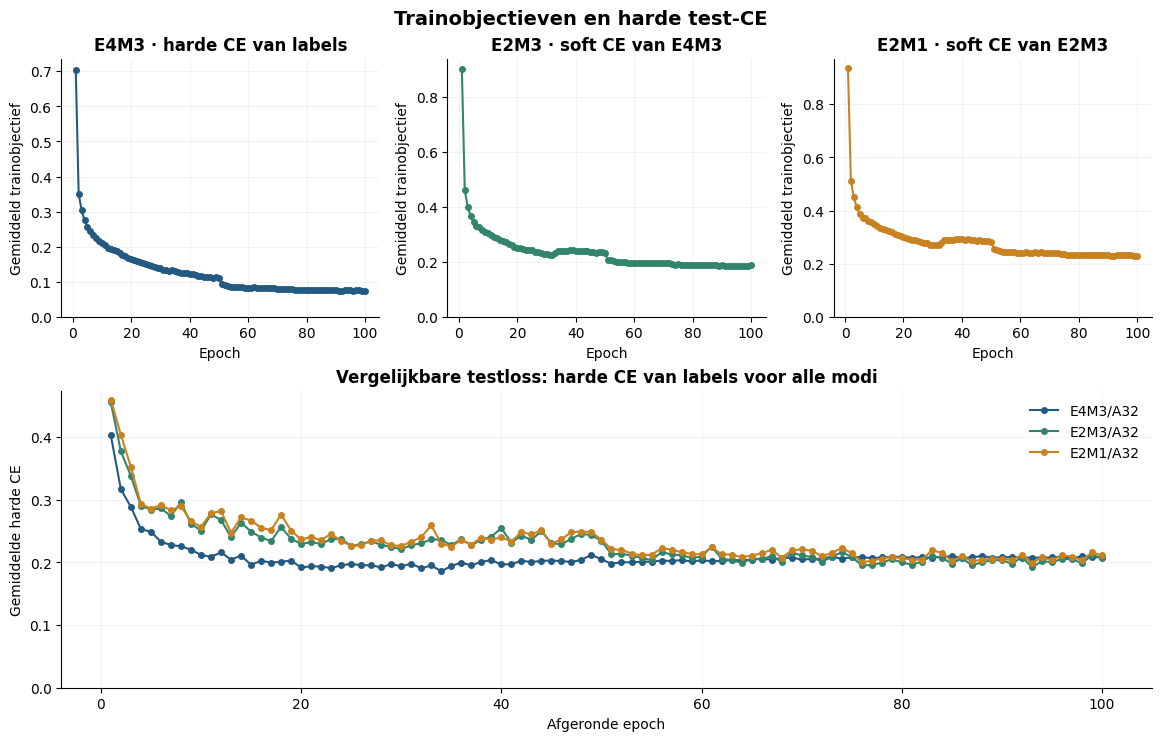

In [6]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.760295,19.587431,94.933159,False,26032,"[1783, 5144, 4120, 2839, 2534, 2345, 1976, 199...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,20.163645,19.587431,94.176398,False,26032,"[1754, 5249, 4055, 2864, 2582, 2311, 2005, 205...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,20.275046,19.587431,93.949754,False,26032,"[1752, 5278, 4050, 2871, 2586, 2306, 2029, 204...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,34,MXFP8_E4M3,10,1,19.587431,19.587431,95.013829,False,26032,"[1756, 5099, 4141, 2852, 2518, 2395, 1973, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,34,MXFP6_E2M3,10,1,20.129072,19.587431,93.192993,False,26032,"[1659, 5240, 4152, 3071, 2595, 2363, 1899, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,34,MXFP4_E2M1,10,1,19.975415,19.587431,93.592502,False,26032,"[1704, 5200, 4170, 3025, 2581, 2335, 1924, 198...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


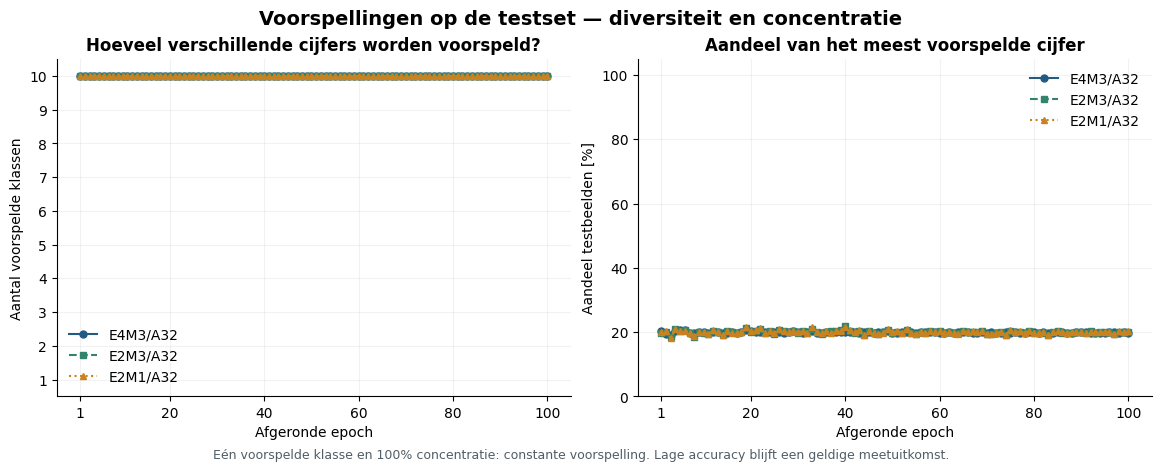

In [7]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Leren de blokkeuzes werkelijk iets?

De schaaldiagnostiek onderscheidt drie vragen: krijgen de FP32-hulpwaarden een gradient, verplaatsen ze zich, en passeren ze de harde grens van 5,5? Een verplaatsing hoeft nog geen andere forwardkeuze te geven. **Geen harde omschakeling is daarom geen technische FAIL**; het is wel relevant voor de interpretatie van deze training.

De eerste grafiek toont het aandeel ×32 per laag. De histogrammen tonen de volledige θ-verdeling bij initialisatie, bij het E4M3-bestcheckpunt en bij de laatste afgeronde epoch. De helper berekent de harde keuzes en samenvattingen opnieuw uit de opgeslagen blokstaat en vergelijkt deze met CSV en history; er wordt geen model geladen.


Op de laatste afgeronde epoch gebruiken **1,647 blokken ×32** en **2,433 blokken ×64** (40.37% ×32; 4,080 blokken totaal). In de laatste epoch veranderden 3,965 FP32-hulpwaarden. Over de opgeslagen training werden 351,037 harde omschakelingen geteld.

Een blok kan meerdere keren wisselen: totaal flips, unieke wisselende blokken binnen een epoch en netto verschil tussen twee epochgrenzen zijn verschillende metingen. Geen omschakeling betekent niet automatisch dat de FP32-hulpwaarden of gradients nul zijn. Dit zijn trainingsdiagnostieken; zij bewijzen geen accuracyverbetering of optimale keuze.

,epoch,layer,blocks,theta_min,theta_max,theta_mean,theta_std,theta_changed_blocks,theta_update_l2,count_x32,count_x64,fraction_x32,net_choice_changes,choice_flips_during_epoch,unique_blocks_switched_during_epoch,projected_values_during_epoch,scale_grad_l2_min,scale_grad_l2_max,scale_grad_nonzero_blocks_max,scale_lr
0,1,layers.3,64,5.841669,6.0,5.952598,0.049783,55,0.549924,0,64,0.000000,0,0,0,7504,0.001558,0.039581,64,0.001000
1,1,layers.6,80,5.753900,6.0,5.949381,0.058034,66,0.688782,0,80,0.000000,0,0,0,8837,0.001481,0.034370,80,0.001000
2,1,layers.10,160,5.821053,6.0,5.956231,0.045887,141,0.802132,0,160,0.000000,0,0,0,16377,0.001220,0.024470,160,0.001000
3,1,layers.13,288,5.820446,6.0,5.960836,0.037562,249,0.920917,0,288,0.000000,0,0,0,26026,0.001073,0.020710,288,0.001000
4,1,layers.16,288,5.819118,6.0,5.959743,0.040101,253,0.964303,0,288,0.000000,0,0,0,28594,0.000894,0.015194,288,0.001000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,100,layers.6,80,5.000000,6.0,5.613511,0.242551,79,0.000229,39,41,0.487500,9,369,29,290,0.011415,0.050682,80,0.000001
596,100,layers.10,160,5.113824,6.0,5.642769,0.213479,157,0.000286,56,104,0.350000,15,613,49,241,0.013699,0.058227,160,0.000001
597,100,layers.13,288,5.004714,6.0,5.642068,0.208720,283,0.000339,104,184,0.361111,44,954,100,282,0.013536,0.051244,288,0.000001
598,100,layers.16,288,5.005095,6.0,5.649742,0.208590,281,0.000352,108,180,0.375000,40,636,95,731,0.008736,0.039778,288,0.000001


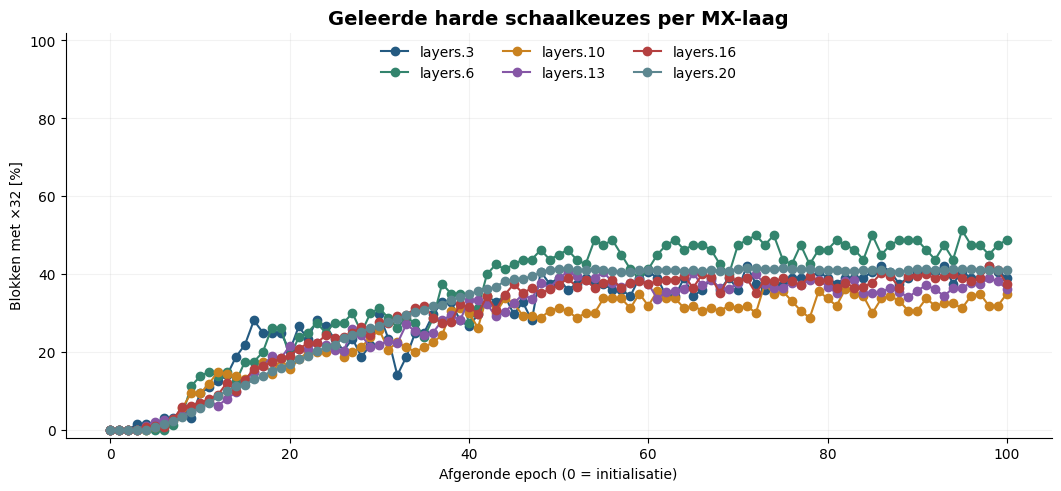

In [8]:
display(Markdown(ns.scale_learning_markdown(run)))
display(ns.scale_table(run).round(8))
figures['scale_choices'] = ns.plot_scale_choices(run)
display(figures['scale_choices'])
plt.close(figures['scale_choices'])


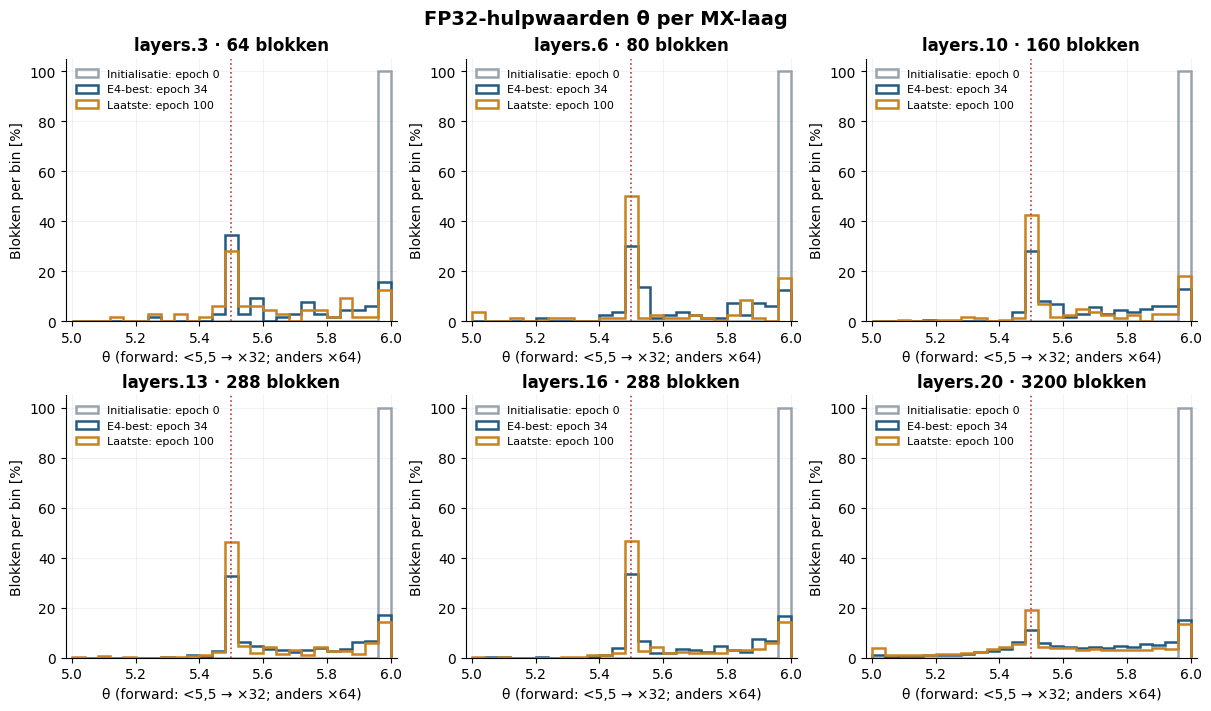

In [9]:
figures['theta_distributions'] = ns.plot_theta_distributions(run)
display(figures['theta_distributions'])
plt.close(figures['theta_distributions'])


### Wissels, gradients en projectie op de grenzen

Het totaal aantal omschakelingen telt iedere wissel na een optimizerupdate. Een blok kan binnen één epoch meerdere keren wisselen. Het aantal unieke wisselende blokken telt ieder blok maximaal één keer per epoch; het netto verschil vergelijkt alleen de twee epochgrenzen. De L2-update is eveneens een netto verschil en geen opgetelde reisafstand.

De gradientgrafiek toont de grootste waargenomen schaalgradientnorm per laag en per epoch, met een symmetrische logschaal die ook nul kan weergeven. De projectietelling telt hoeveel θ-waarden na Adam buiten het interval vielen en werden teruggezet, inclusief herhaalde projecties van hetzelfde blok. Deze tellingen bewijzen op zichzelf geen accuracywinst.


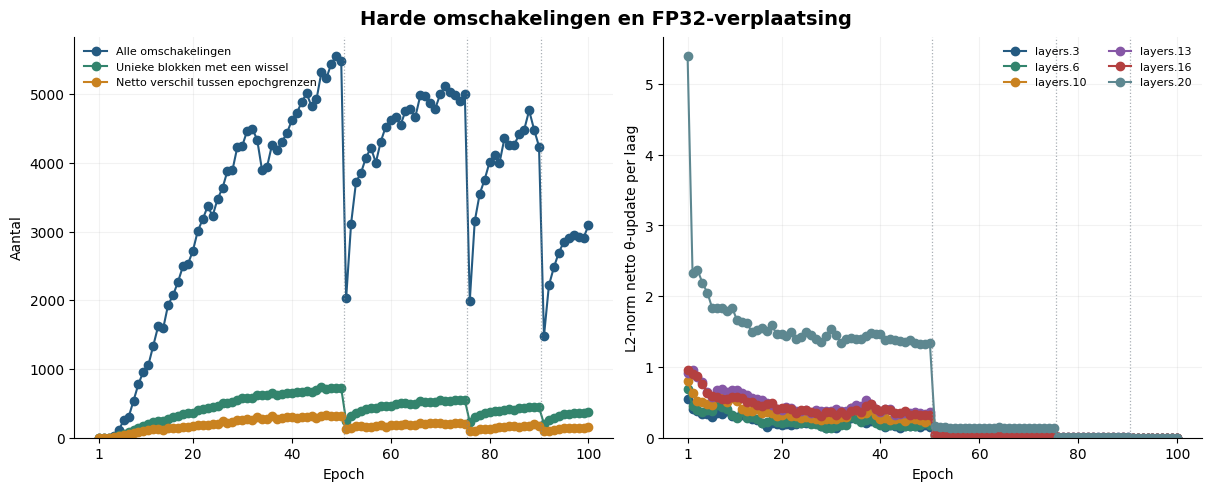

In [10]:
figures['scale_switches'] = ns.plot_scale_switches(run)
display(figures['scale_switches'])
plt.close(figures['scale_switches'])


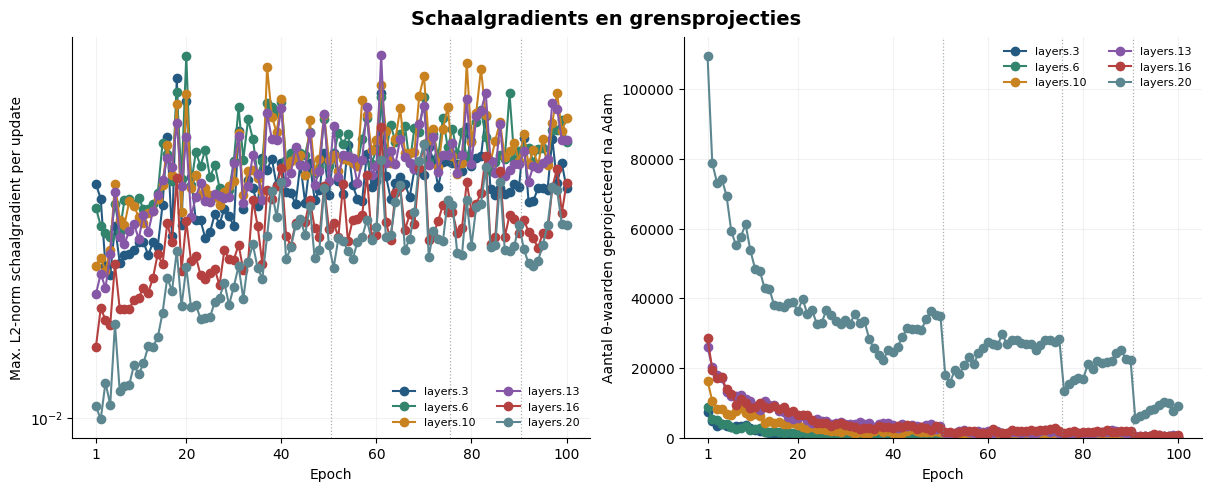

In [11]:
figures['scale_gradients'] = ns.plot_scale_gradients(run)
display(figures['scale_gradients'])
plt.close(figures['scale_gradients'])


## Gemeten trainingsduur en status van de honderd epochs

**Gemeten som over 100 afgeronde epochs: 7037.48 s (117.29 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

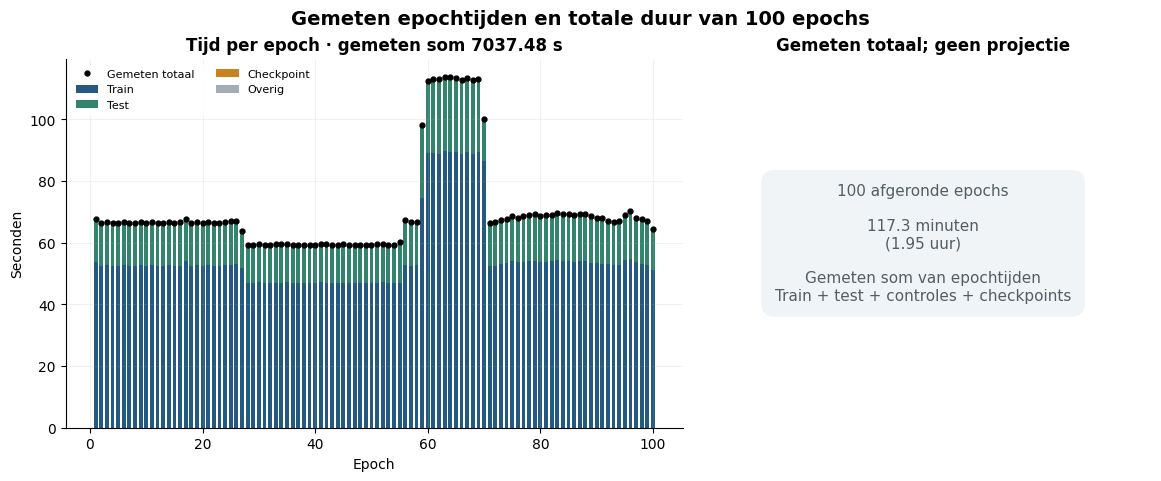

In [12]:
display(Markdown('## Gemeten trainingsduur en status van de honderd epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

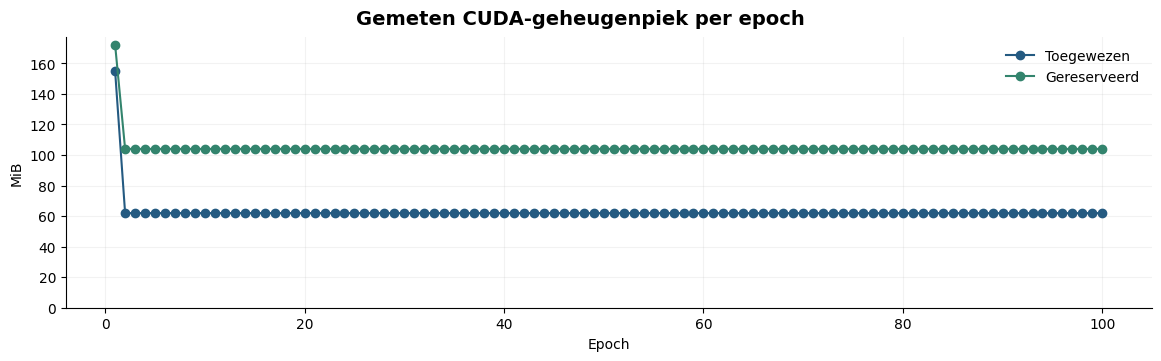

In [13]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [14]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten gecontroleerd,True
2,Geleerde schaalcorrectie ingeschakeld,True
3,Schaalkeuzes en θ-staten onafhankelijk consistent,True
4,E2M1 behoudt de E2M3-schaal,True
5,Eén E4-bron per laag en minibatch,True
6,Broncache leeg vóór iedere optimizerupdate,True
7,BN-tellers correct in elke opgeslagen epoch,True
8,Evaluatie zonder optimizerupdates,True
9,Bronbestanden ongewijzigd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.508961,torch.float32,1065,0
1,1,MXFP6_E2M3,layers.3,1728,1.508961,torch.float32,1555,0
2,1,MXFP8_E4M3,layers.3,1728,1.508961,torch.float32,1630,0
3,1,MXFP4_E2M1,layers.6,2304,1.729783,torch.float32,1435,0
4,1,MXFP6_E2M3,layers.6,2304,1.729783,torch.float32,2073,0
...,...,...,...,...,...,...,...,...
1795,100,MXFP6_E2M3,layers.16,9213,0.001960,torch.float32,190,40
1796,100,MXFP8_E4M3,layers.16,9213,0.001960,torch.float32,192,0
1797,100,MXFP4_E2M1,layers.20,100766,0.006643,torch.float32,231,44
1798,100,MXFP6_E2M3,layers.20,100766,0.006643,torch.float32,846,44


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes MX-masters afwezig,FP32-schaalproxies afwezig,Gepakte keuze-informatie [bytes],Eigen schaaloffsets,E4-bronschaal behouden,Afgeleid uit opgeslagen bron,Masters gelezen voor afleiding,Volledige testset opnieuw uitgevoerd,Bron-SHA256
0,best_E4M3_test,34,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,199385,True,True,True,510,[0],True,False,False,False,40f77d9edef64e3fd6589a175f34ca29afd2358a18c3e5...
1,best_E4M3_test,34,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,167513,True,True,True,510,"[5, 6]",False,True,False,False,40f77d9edef64e3fd6589a175f34ca29afd2358a18c3e5...
2,best_E4M3_test,34,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,134873,True,True,True,510,"[5, 6]",False,True,False,False,40f77d9edef64e3fd6589a175f34ca29afd2358a18c3e5...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,199385,True,True,True,510,[0],True,False,False,False,26243e8a7a252e5b945bdbea9b77b764fd5badb196cc01...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,167513,True,True,True,510,"[5, 6]",False,True,False,False,26243e8a7a252e5b945bdbea9b77b764fd5badb196cc01...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,134873,True,True,True,510,"[5, 6]",False,True,False,False,26243e8a7a252e5b945bdbea9b77b764fd5badb196cc01...


## Interpretatie en grenzen

De gerichte wijziging tegenover de vaste correcties is dat beide lagere modi hun blokoffset **samen uit +5 of +6 kiezen**, gestuurd door een FP32-hulpwaarde met expliciete benaderde gradient. De E4M3-broncodes en bronschaal blijven volgens dezelfde encoder bepaald. De mantissatruncatie behoudt de E2M3-schaal. De identity-STE naar de mastergewichten blijft behouden, zonder extra factor32/64 in die mastergradient. De afzonderlijke schaalgradient krijgt de som van de twee lagere bijdragen; de detached teacher geeft geen gradient terug naar zijn eigen hogere pass.

Een lage accuracy, constante voorspelling of nul harde wissels blijft een onderzoeksuitkomst wanneer de technische controles slagen. Een dalende soft-target trainingsloss bewijst op zichzelf geen betere classificatie. Beoordeel testaccuracy, harde test-CE, voorspeldistributie en schaalgedrag samen. De proef onderzoekt uitsluitend de keuze tussen ×32 en ×64; zij bewijst niet dat dit de optimale schaalruimte, gradientbenadering of leersnelheid is.

De tijdgrafiek geeft gemeten epochtijden. Bij een volledige run wordt de gemeten som over honderd epochs getoond. Bij een onderbroken run blijft een eventuele projectie nadrukkelijk onderscheiden van metingen. CUDA-uitvoering volgt het bestaande protocol met cuDNN benchmark en heeft geen bitexacte hervatgarantie. De extra FP32-hulpwaarden en Adam-toestand bestaan tijdens training; compacte exports bewaren alleen de harde blokkeuzes. De getoonde GPU-piek is een frameworkmeting en geen bewijs van native MX-kernels of hardwareversnelling.


De gewichten en schaalhulpwaarden gebruiken hetzelfde leersnelheidsschema: 0,001 tijdens epochs 1–50, 0,0001 tijdens 51–75, 0,00001 tijdens 76–90 en 0,000001 tijdens 91–100. De stippellijnen in de epochgrafieken markeren de drie overgangen.


In [15]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_learned_scale32_64_reference100\20261025_150724_515132_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,scale_epoch_metrics.csv
